# 03 – Baseline: Random Forest không xử lý mất cân bằng

**Đầu vào:** `data/processed/train.pkl`, `test.pkl`.
**Đầu ra:** không ghi file; kết quả là mốc so sánh.

Đo xem khi chưa xử lý mất cân bằng, mô hình bỏ sót các lớp hiếm đến mức nào. Đây là cấu hình Random Forest + Không xử lý trong ma trận thí nghiệm; notebook 04 chạy lại cấu hình này với cùng `random_state` và phải ra cùng kết quả.

In [11]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import pandas as pd
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("../data")
RANDOM_STATE = 42
CLASS_ORDER = ["BENIGN", "DoS", "PortScan", "DDoS", "Brute Force", "Web Attack", "Bot", "Infiltration", "Heartbleed"]

## 1. Đọc dữ liệu

Dùng bản chia train/test đã lưu ở notebook 02.

In [12]:
train = pd.read_pickle(DATA_DIR / "processed" / "train.pkl")
test = pd.read_pickle(DATA_DIR / "processed" / "test.pkl")

X_train, y_train = train.drop(columns="Label"), train["Label"]
X_test, y_test = test.drop(columns="Label"), test["Label"]

print(f"Train: {X_train.shape[0]:,} rows × {X_train.shape[1]} features")
print(f"Test:  {X_test.shape[0]:,} rows × {X_test.shape[1]} features")
pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()}).reindex(CLASS_ORDER)

Train: 566,932 rows × 68 features
Test:  141,733 rows × 68 features


,Train,Test
Label,,
BENIGN,297985,74497
DoS,154868,38717
PortScan,1480,370
DDoS,102409,25602
Brute Force,7320,1830
Web Attack,1714,429
Bot,1118,279
Infiltration,29,7
Heartbleed,9,2


## 2. Mô hình

`StandardScaler` → `RandomForestClassifier`, đặt trong `Pipeline` của imbalanced-learn để notebook 04 chèn được bước resample (bước này chỉ chạy khi `fit`).

- Chuẩn hóa không đổi kết quả của Random Forest, vì phép chia nhánh theo ngưỡng không phụ thuộc thang đo. Vẫn giữ để mọi cấu hình dùng chung một Pipeline: KNN, SMOTE (dựa trên khoảng cách) và Logistic Regression cần chuẩn hóa.
- Tham số: `n_estimators=100`, `n_jobs=-1`, `random_state=42`; còn lại mặc định (bootstrap, mỗi lần chia xét √68 ≈ 8 đặc trưng, cây không giới hạn độ sâu).

In [13]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)),
])
model

,steps,"[('scaler', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'


## 3. Huấn luyện

`fit` chỉ trên train. Thời gian train được ghi lại để so với các cách xử lý ở notebook 04 (khoảng 20 giây).

In [ ]:
start = time.perf_counter()
model.fit(X_train, y_train)
train_time = time.perf_counter() - start
print(f"Training time: {train_time:.1f} s")

## 4. Dự đoán trên test

Tập test (141.733 flow) chỉ được dùng từ bước này.

In [ ]:
start = time.perf_counter()
y_pred = model.predict(X_test)
predict_time = time.perf_counter() - start
print(f"Prediction time for {len(X_test):,} flows: {predict_time:.1f} s")

Prediction time for 141,733 flows: 0.3 s


## 5. Accuracy và macro-F1

Macro-F1 là trung bình không trọng số của F1 trên 9 lớp, nên Heartbleed (2 mẫu test) nặng ngang BENIGN (74.497). Accuracy bị chi phối bởi BENIGN, DoS, DDoS (khoảng 98% tập test) nên chỉ để tham khảo.

In [ ]:
acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")
print(f"Accuracy (reference only): {acc:.4f}")
print(f"Macro-F1 (main metric):    {macro_f1:.4f}")

Accuracy (reference only): 0.9985
Macro-F1 (main metric):    0.9633


## 6. Precision, recall, F1 từng lớp

Với IDS, recall thấp nghĩa là bỏ sót tấn công, precision thấp nghĩa là báo động nhầm. `zero_division=0`: lớp không được dự đoán lần nào thì precision ghi 0 thay vì lỗi 0/0.

In [ ]:
report = pd.DataFrame(
    classification_report(y_test, y_pred, labels=CLASS_ORDER, output_dict=True, zero_division=0)
).T
report = report.loc[CLASS_ORDER, ["precision", "recall", "f1-score", "support"]]
report["support"] = report["support"].astype(int)
report.round(4)

,precision,recall,f1-score,support
BENIGN,0.9980,0.9992,0.9986,74497
DoS,0.9992,0.9983,0.9988,38717
PortScan,0.9918,0.9838,0.9878,370
DDoS,0.9996,0.9996,0.9996,25602
Brute Force,0.9989,0.9973,0.9981,1830
Web Attack,0.9976,0.9534,0.9750,429
Bot,0.9317,0.8315,0.8788,279
Infiltration,1.0000,0.7143,0.8333,7
Heartbleed,1.0000,1.0000,1.0000,2


## 7. Confusion matrix

Hàng là nhãn thật, cột là nhãn dự đoán. Bảng số đếm cho biết từng lớp bị nhầm thành lớp nào; hình chuẩn hóa theo hàng nên đường chéo là recall.

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=CLASS_ORDER)
pd.DataFrame(
    cm,
    index=pd.Index(CLASS_ORDER, name="True label"),
    columns=pd.Index(CLASS_ORDER, name="Predicted label"),
)

Predicted label,BENIGN,DoS,PortScan,DDoS,Brute Force,Web Attack,Bot,Infiltration,Heartbleed
True label,,,,,,,,,
BENIGN,74439,28,1,10,2,0,17,0,0
DoS,60,38653,2,1,0,1,0,0,0
PortScan,3,3,364,0,0,0,0,0,0
DDoS,10,0,0,25592,0,0,0,0,0
Brute Force,5,0,0,0,1825,0,0,0,0
Web Attack,20,0,0,0,0,409,0,0,0
Bot,47,0,0,0,0,0,232,0,0
Infiltration,2,0,0,0,0,0,0,5,0
Heartbleed,0,0,0,0,0,0,0,0,2


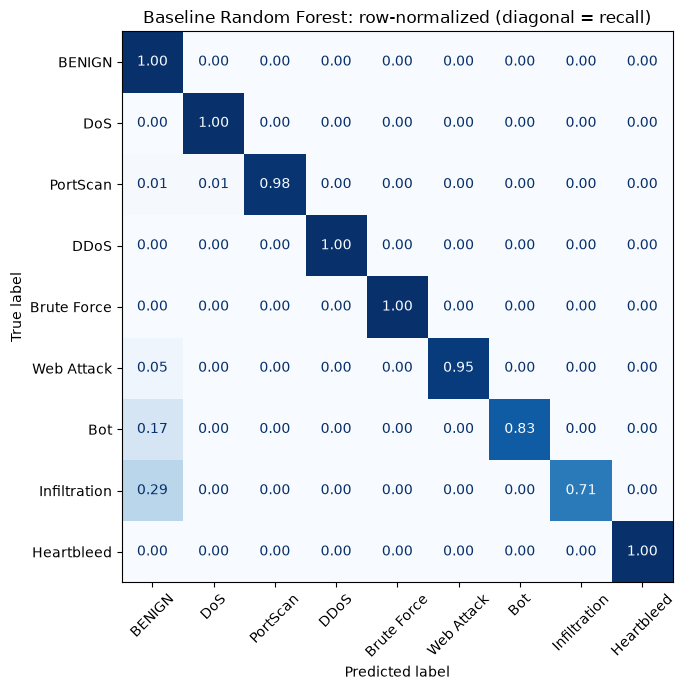

In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=CLASS_ORDER, normalize="true", values_format=".2f",
    cmap="Blues", xticks_rotation=45, colorbar=False, ax=ax,
)
ax.set_title("Baseline Random Forest: row-normalized (diagonal = recall)")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

## 8. Lớp hiếm

Test chỉ có 2 mẫu Heartbleed và 7 mẫu Infiltration: mỗi mẫu làm recall đổi 50 và khoảng 14 điểm phần trăm. Với các lớp này ghi số đếm (ví dụ 5/7) và xem mẫu sai bị nhầm thành lớp nào.

In [ ]:
for label in ["Heartbleed", "Infiltration", "Bot", "PortScan", "Web Attack"]:
    mask = (y_test == label).to_numpy()
    preds = pd.Series(y_pred[mask])
    n_correct = int((preds == label).sum())
    wrong = preds[preds != label].value_counts()
    line = f"{label:<13} correct {n_correct}/{mask.sum()}"
    if len(wrong):
        line += " | misclassified as: " + ", ".join(f"{k} {v}" for k, v in wrong.items())
    print(line)

Heartbleed    correct 2/2
Infiltration  correct 5/7 | misclassified as: BENIGN 2
Bot           correct 232/279 | misclassified as: BENIGN 47
PortScan      correct 364/370 | misclassified as: BENIGN 3, DoS 3
Web Attack    correct 409/429 | misclassified as: BENIGN 20
